In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "customer_modeling_dataset.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Unique customers:", df["CUSTOMER_ID"].nunique())

Dataset shape: (2600, 35)
Unique customers: 2600


In [2]:
print("Target distribution:")
print(df["CHURNED"].value_counts())

print("\nTarget proportions:")
print(
    df["CHURNED"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target distribution:
CHURNED
0    1782
1     818
Name: count, dtype: int64

Target proportions:
CHURNED
0    68.54
1    31.46
Name: proportion, dtype: float64


In [3]:
DROP_COLS = [
    "CUSTOMER_ID",
    "CHURNED",
    "SIGNUP_DATE",
    "LAST_PURCHASE_MONTH"
]

X = df.drop(columns=DROP_COLS)
y = df["CHURNED"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
for col in X.columns:
    print("-", col)

X shape: (2600, 31)
y shape: (2600,)

Feature columns:
- AGE
- GENDER
- CITY
- MEMBERSHIP_TIER
- MARKETING_OPT_IN
- PREFERRED_STORE_ID
- PREFERRED_CATEGORY
- HOME_STORE_PRICE_TIER
- total_transactions
- total_spend
- avg_basket_value
- active_months
- observed_months
- RECENCY_MONTHS
- NO_HISTORICAL_PURCHASE
- avg_app_sessions
- total_app_sessions
- avg_emails_opened
- total_emails_opened
- total_coupons_redeemed
- avg_distinct_categories
- avg_promo_txn_pct
- total_support_tickets
- avg_support_tickets
- complaint_count
- complaint_rate
- has_complaint
- NO_PRELABEL_ACTIVITY
- SIGNUP_YEAR
- SIGNUP_MONTH
- CUSTOMER_TENURE_MONTHS


In [4]:
cohort_summary = (
    df.groupby("SIGNUP_YEAR")
    .agg(
        customers=("CUSTOMER_ID", "count"),
        churned=("CHURNED", "sum"),
        churn_rate=("CHURNED", "mean")
    )
    .reset_index()
)

cohort_summary["churn_rate"] *= 100

display(cohort_summary)

,SIGNUP_YEAR,customers,churned,churn_rate
0,2021,745,279,37.449664
1,2022,792,306,38.636364
2,2023,816,229,28.063725
3,2024,247,4,1.619433


In [5]:
train_mask = df["SIGNUP_YEAR"].isin([2021, 2022])
val_mask = df["SIGNUP_YEAR"] == 2023
test_mask = df["SIGNUP_YEAR"] == 2024

train_df = df[train_mask].copy()
val_df = df[val_mask].copy()
test_df = df[test_mask].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain target:")
print(train_df["CHURNED"].value_counts())

print("\nValidation target:")
print(val_df["CHURNED"].value_counts())

print("\nTest target:")
print(test_df["CHURNED"].value_counts())

Train: (1537, 35)
Validation: (816, 35)
Test: (247, 35)

Train target:
CHURNED
0    952
1    585
Name: count, dtype: int64

Validation target:
CHURNED
0    587
1    229
Name: count, dtype: int64

Test target:
CHURNED
0    243
1      4
Name: count, dtype: int64


# preprocessing pipeline

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DROP_COLS = [
    "CUSTOMER_ID",
    "CHURNED",
    "SIGNUP_DATE",
    "LAST_PURCHASE_MONTH"
]

X_train = train_df.drop(columns=DROP_COLS)
y_train = train_df["CHURNED"]

X_val = val_df.drop(columns=DROP_COLS)
y_val = val_df["CHURNED"]

X_test = test_df.drop(columns=DROP_COLS)
y_test = test_df["CHURNED"]

categorical_features = [
    "GENDER",
    "CITY",
    "MEMBERSHIP_TIER",
    "PREFERRED_STORE_ID",
    "PREFERRED_CATEGORY",
    "HOME_STORE_PRICE_TIER"
]

numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical:")
print(categorical_features)

print("\nNumeric:")
print(numeric_features)

Numeric features: 25
Categorical features: 6

Categorical:
['GENDER', 'CITY', 'MEMBERSHIP_TIER', 'PREFERRED_STORE_ID', 'PREFERRED_CATEGORY', 'HOME_STORE_PRICE_TIER']

Numeric:
['AGE', 'MARKETING_OPT_IN', 'total_transactions', 'total_spend', 'avg_basket_value', 'active_months', 'observed_months', 'RECENCY_MONTHS', 'NO_HISTORICAL_PURCHASE', 'avg_app_sessions', 'total_app_sessions', 'avg_emails_opened', 'total_emails_opened', 'total_coupons_redeemed', 'avg_distinct_categories', 'avg_promo_txn_pct', 'total_support_tickets', 'avg_support_tickets', 'complaint_count', 'complaint_rate', 'has_complaint', 'NO_PRELABEL_ACTIVITY', 'SIGNUP_YEAR', 'SIGNUP_MONTH', 'CUSTOMER_TENURE_MONTHS']


In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [8]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed train shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed test shape:", X_test_processed.shape)

print(
    "Missing values after preprocessing:",
    np.isnan(X_train_processed).sum()
)

Processed train shape: (1537, 94)
Processed validation shape: (816, 94)
Processed test shape: (247, 94)
Missing values after preprocessing: 0


# Logistic Regression

In [9]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [10]:
val_prob_lr = logistic_model.predict_proba(X_val)[:, 1]
val_pred_lr = logistic_model.predict(X_val)

print("First 10 churn probabilities:")
print(np.round(val_prob_lr[:10], 4))

print("\nFirst 10 predictions:")
print(val_pred_lr[:10])

First 10 churn probabilities:
[0.991  0.0783 0.9973 0.9804 1.     0.0746 0.978  0.9999 1.     0.4048]

First 10 predictions:
[1 0 1 1 1 0 1 1 1 0]


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

lr_metrics = {
    "Accuracy": accuracy_score(y_val, val_pred_lr),
    "Precision": precision_score(y_val, val_pred_lr),
    "Recall": recall_score(y_val, val_pred_lr),
    "F1": f1_score(y_val, val_pred_lr),
    "PR-AUC": average_precision_score(y_val, val_prob_lr)
}

print("Logistic Regression — Validation Results")
print("-" * 45)

for metric, value in lr_metrics.items():
    print(f"{metric:12s}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred_lr))

Logistic Regression — Validation Results
---------------------------------------------
Accuracy    : 0.4069
Precision   : 0.3207
Recall      : 0.9956
F1          : 0.4851
PR-AUC      : 0.4188

Confusion Matrix:
[[104 483]
 [  1 228]]


# random forest

In [12]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [13]:
val_prob_rf = random_forest_model.predict_proba(X_val)[:, 1]
val_pred_rf = random_forest_model.predict(X_val)

print("First 10 Random Forest probabilities:")
print(np.round(val_prob_rf[:10], 4))

First 10 Random Forest probabilities:
[0.505  0.1107 0.5409 0.9449 0.6328 0.1134 0.7348 0.7877 0.79   0.3489]


In [14]:
rf_metrics = {
    "Accuracy": accuracy_score(y_val, val_pred_rf),
    "Precision": precision_score(y_val, val_pred_rf),
    "Recall": recall_score(y_val, val_pred_rf),
    "F1": f1_score(y_val, val_pred_rf),
    "PR-AUC": average_precision_score(y_val, val_prob_rf)
}

print("Random Forest — Validation Results")
print("-" * 45)

for metric, value in rf_metrics.items():
    print(f"{metric:12s}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred_rf))

Random Forest — Validation Results
---------------------------------------------
Accuracy    : 0.5490
Precision   : 0.3828
Recall      : 0.9913
F1          : 0.5523
PR-AUC      : 0.9348

Confusion Matrix:
[[221 366]
 [  2 227]]


In [15]:
from sklearn.ensemble import HistGradientBoostingClassifier

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

hgb_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42
)

hgb_model.fit(
    X_train_processed,
    y_train
)

print("HistGradientBoosting trained successfully.")

HistGradientBoosting trained successfully.


In [16]:
val_prob_hgb = hgb_model.predict_proba(
    X_val_processed
)[:, 1]

val_pred_hgb = (
    val_prob_hgb >= 0.5
).astype(int)

In [17]:
hgb_metrics = {
    "Accuracy": accuracy_score(y_val, val_pred_hgb),
    "Precision": precision_score(y_val, val_pred_hgb),
    "Recall": recall_score(y_val, val_pred_hgb),
    "F1": f1_score(y_val, val_pred_hgb),
    "PR-AUC": average_precision_score(
        y_val,
        val_prob_hgb
    )
}

print("HistGradientBoosting — Validation Results")
print("-" * 50)

for metric, value in hgb_metrics.items():
    print(f"{metric:12s}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred_hgb))

HistGradientBoosting — Validation Results
--------------------------------------------------
Accuracy    : 0.8897
Precision   : 0.7509
Recall      : 0.9083
F1          : 0.8221
PR-AUC      : 0.9382

Confusion Matrix:
[[518  69]
 [ 21 208]]


In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.05):
    pred = (val_prob_hgb >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred)
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)

,Threshold,Precision,Recall,F1
0,0.20,0.5860,0.9520,0.7255
1,0.25,0.6068,0.9301,0.7345
2,0.30,0.6463,0.9258,0.7612
3,0.35,0.6795,0.9258,0.7837
4,0.40,0.7119,0.9170,0.8015
5,0.45,0.7359,0.9127,0.8148
6,0.50,0.7509,0.9083,0.8221
7,0.55,0.7803,0.8996,0.8357
8,0.60,0.7984,0.8821,0.8382
9,0.65,0.8171,0.8777,0.8463


In [19]:
thresholds = np.arange(0.05, 0.96, 0.01)

exact_threshold_results = []

for threshold in thresholds:
    pred = (val_prob_hgb >= threshold).astype(int)

    exact_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred)
    })

exact_threshold_df = pd.DataFrame(exact_threshold_results)

best_row = exact_threshold_df.loc[
    exact_threshold_df["F1"].idxmax()
]

print("Best validation threshold by F1:")
display(best_row.to_frame().T.round(4))

Best validation threshold by F1:


,Threshold,Precision,Recall,F1
86,0.91,0.9268,0.8297,0.8756


In [20]:
# Transform untouched 2024 test cohort
X_test_processed = preprocessor.transform(X_test)

# HGB probability predictions
test_prob_hgb = hgb_model.predict_proba(
    X_test_processed
)[:, 1]

# Standard 0.50 classification
test_pred_05 = (
    test_prob_hgb >= 0.50
).astype(int)

# Validation-selected threshold
BEST_THRESHOLD = 0.91

test_pred_selected = (
    test_prob_hgb >= BEST_THRESHOLD
).astype(int)

print("2024 test probability summary:")
print(pd.Series(test_prob_hgb).describe())

2024 test probability summary:
count    247.000000
mean       0.141333
std        0.143753
min        0.002547
25%        0.053911
50%        0.097750
75%        0.170114
max        0.930444
dtype: float64


In [21]:
print("=== 2024 TEST — Threshold 0.50 ===")

print("Accuracy :", accuracy_score(y_test, test_pred_05))
print("Precision:", precision_score(y_test, test_pred_05, zero_division=0))
print("Recall   :", recall_score(y_test, test_pred_05, zero_division=0))
print("F1       :", f1_score(y_test, test_pred_05, zero_division=0))
print("PR-AUC   :", average_precision_score(y_test, test_prob_hgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred_05))


print("\n\n=== 2024 TEST — Threshold 0.91 ===")

print("Accuracy :", accuracy_score(y_test, test_pred_selected))
print("Precision:", precision_score(y_test, test_pred_selected, zero_division=0))
print("Recall   :", recall_score(y_test, test_pred_selected, zero_division=0))
print("F1       :", f1_score(y_test, test_pred_selected, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred_selected))

=== 2024 TEST — Threshold 0.50 ===
Accuracy : 0.9838056680161943
Precision: 0.5
Recall   : 1.0
F1       : 0.6666666666666666
PR-AUC   : 0.7678571428571428

Confusion Matrix:
[[239   4]
 [  0   4]]


=== 2024 TEST — Threshold 0.91 ===
Accuracy : 0.9878542510121457
Precision: 1.0
Recall   : 0.25
F1       : 0.4

Confusion Matrix:
[[243   0]
 [  3   1]]


#
HistGradientBoosting achieved a validation PR-AUC of 0.9382 and F1 of 0.8221 at the default 0.50 threshold. Threshold analysis on the 2023 validation cohort produced a maximum F1 of 0.8756 at a threshold of 0.91; however, when applied unchanged to the 2024 holdout cohort, this threshold reduced recall to 25%. At the standard 0.50 threshold, the model identified all four observed 2024 churners, with PR-AUC of 0.7679. Because the 2024 cohort contains only four positive cases and has substantially shorter customer histories, these holdout metrics should be interpreted cautiously.

In [42]:
print("=== 2024 TEST — Threshold 0.50 ===")

print("Accuracy :", accuracy_score(y_test, test_pred_05))
print("Precision:", precision_score(y_test, test_pred_05, zero_division=0))
print("Recall   :", recall_score(y_test, test_pred_05, zero_division=0))
print("F1       :", f1_score(y_test, test_pred_05, zero_division=0))
print("PR-AUC   :", average_precision_score(y_test, test_prob_hgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred_05))


print("\n\n=== 2024 TEST — Threshold 0.91 ===")

print("Accuracy :", accuracy_score(y_test, test_pred_selected))
print("Precision:", precision_score(y_test, test_pred_selected, zero_division=0))
print("Recall   :", recall_score(y_test, test_pred_selected, zero_division=0))
print("F1       :", f1_score(y_test, test_pred_selected, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred_selected))

=== 2024 TEST — Threshold 0.50 ===
Accuracy : 0.9838056680161943
Precision: 0.5
Recall   : 1.0
F1       : 0.6666666666666666
PR-AUC   : 0.7678571428571428

Confusion Matrix:
[[239   4]
 [  0   4]]


=== 2024 TEST — Threshold 0.91 ===
Accuracy : 0.9878542510121457
Precision: 1.0
Recall   : 0.25
F1       : 0.4

Confusion Matrix:
[[243   0]
 [  3   1]]


In [ ]:
import joblib
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "hist_gradient_boosting_model.joblib"
)

PREPROCESSOR_PATH = (
    PROJECT_ROOT
    / "models"
    / "hgb_preprocessor.joblib"
)

# Make sure models folder exists
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

# Save model
joblib.dump(
    hgb_model,
    MODEL_PATH
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    PREPROCESSOR_PATH
)

print("Model saved successfully:")
print(MODEL_PATH)

print("\nPreprocessor saved successfully:")
print(PREPROCESSOR_PATH)

Model saved successfully:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\models\hist_gradient_boosting_model.joblib

Preprocessor saved successfully:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\models\hgb_preprocessor.joblib


: 

In [22]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.49.1


In [23]:
# Use the already-preprocessed 2023 validation data
X_val_processed_df = pd.DataFrame(
    X_val_processed,
    columns=preprocessor.get_feature_names_out()
)

print("SHAP input shape:", X_val_processed_df.shape)
print("Feature count:", len(X_val_processed_df.columns))

SHAP input shape: (816, 94)
Feature count: 94


In [24]:
explainer = shap.TreeExplainer(hgb_model)

shap_values = explainer.shap_values(
    X_val_processed_df
)

print("SHAP values shape:", np.array(shap_values).shape)

SHAP values shape: (816, 94)


In [25]:
shap_importance = pd.DataFrame({
    "feature": X_val_processed_df.columns,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(shap_importance.head(20))

,feature,mean_abs_shap
0,num__RECENCY_MONTHS,4.104578
1,num__total_transactions,0.845772
2,num__observed_months,0.600471
3,num__total_app_sessions,0.438006
4,num__avg_emails_opened,0.390948
5,num__avg_basket_value,0.381464
6,num__avg_support_tickets,0.325904
7,num__CUSTOMER_TENURE_MONTHS,0.289612
8,num__avg_app_sessions,0.284384
9,num__total_spend,0.217382


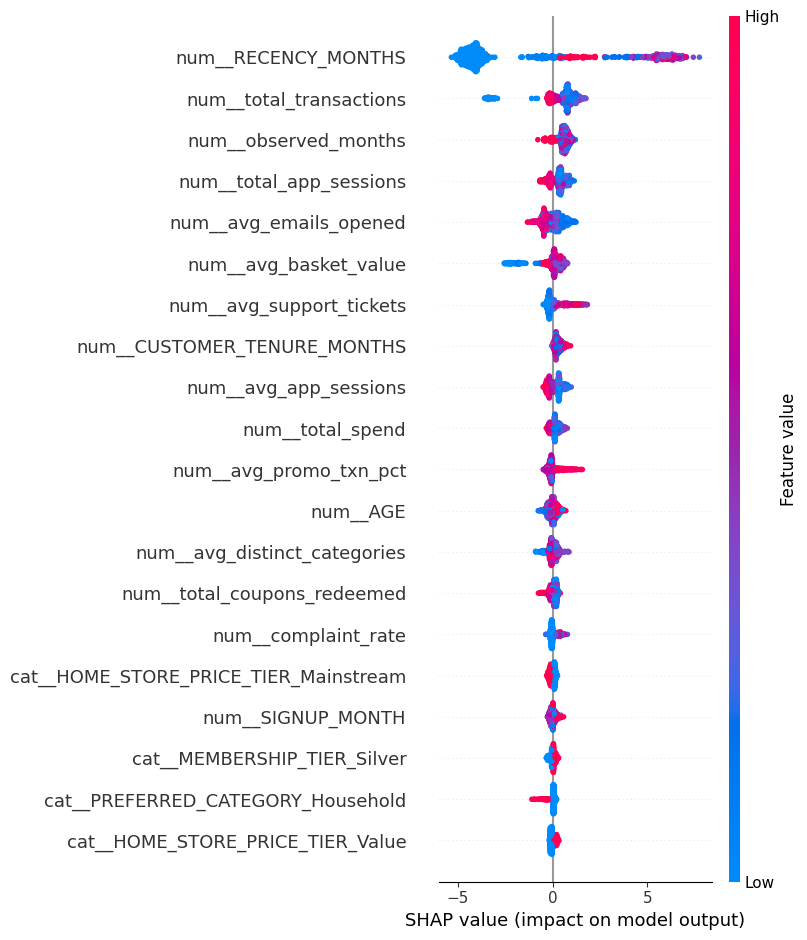

In [26]:
shap.summary_plot(
    shap_values,
    X_val_processed_df,
    max_display=20
)

In [27]:
driver_summary = pd.DataFrame({
    "Business_Driver": [
        "Purchase recency",
        "Purchase frequency",
        "Historical engagement",
        "App engagement",
        "Email engagement",
        "Purchase value",
        "Support interaction",
        "Customer tenure",
        "Digital engagement",
        "Overall spending"
    ],
    "Model_Feature": [
        "RECENCY_MONTHS",
        "total_transactions",
        "observed_months",
        "total_app_sessions",
        "avg_emails_opened",
        "avg_basket_value",
        "avg_support_tickets",
        "CUSTOMER_TENURE_MONTHS",
        "avg_app_sessions",
        "total_spend"
    ],
    "Mean_Abs_SHAP": [
        4.104578,
        0.845772,
        0.600471,
        0.438006,
        0.390948,
        0.381464,
        0.325904,
        0.289612,
        0.284384,
        0.217382
    ]
})

display(driver_summary)

,Business_Driver,Model_Feature,Mean_Abs_SHAP
0,Purchase recency,RECENCY_MONTHS,4.104578
1,Purchase frequency,total_transactions,0.845772
2,Historical engagement,observed_months,0.600471
3,App engagement,total_app_sessions,0.438006
4,Email engagement,avg_emails_opened,0.390948
5,Purchase value,avg_basket_value,0.381464
6,Support interaction,avg_support_tickets,0.325904
7,Customer tenure,CUSTOMER_TENURE_MONTHS,0.289612
8,Digital engagement,avg_app_sessions,0.284384
9,Overall spending,total_spend,0.217382


In [31]:
from pathlib import Path

DRIVER_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "shap_global_feature_importance.csv"
)

DRIVER_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

driver_summary.to_csv(
    DRIVER_PATH,
    index=False
)

print("Saved:", DRIVER_PATH)

Saved: c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\tables\shap_global_feature_importance.csv


In [32]:
profile_features = [
    "AGE",
    "GENDER",
    "CITY",
    "MEMBERSHIP_TIER",
    "MARKETING_OPT_IN",
    "PREFERRED_STORE_ID",
    "PREFERRED_CATEGORY",
    "HOME_STORE_PRICE_TIER",
    "SIGNUP_YEAR",
    "SIGNUP_MONTH",
    "CUSTOMER_TENURE_MONTHS"
]

rfm_features_list = [
    "total_transactions",
    "total_spend",
    "avg_basket_value",
    "active_months",
    "observed_months",
    "RECENCY_MONTHS",
    "NO_HISTORICAL_PURCHASE",
    "NO_PRELABEL_ACTIVITY"
]

behaviour_features = [
    "avg_app_sessions",
    "total_app_sessions",
    "avg_emails_opened",
    "total_emails_opened",
    "total_coupons_redeemed",
    "avg_distinct_categories",
    "avg_promo_txn_pct",
    "total_support_tickets",
    "avg_support_tickets",
    "complaint_count",
    "complaint_rate",
    "has_complaint"
]

ablation_groups = {
    "Profile Only": profile_features,
    "Profile + RFM": profile_features + rfm_features_list,
    "Full Behavioural": (
        profile_features
        + rfm_features_list
        + behaviour_features
    )
}

for name, features in ablation_groups.items():
    print(f"{name}: {len(features)} features")

Profile Only: 11 features
Profile + RFM: 19 features
Full Behavioural: 31 features


In [33]:
profile_cols = ablation_groups["Profile Only"]

X_train_profile = train_df[profile_cols]
X_val_profile = val_df[profile_cols]

profile_categorical = [
    col for col in profile_cols
    if col in categorical_features
]

profile_numeric = [
    col for col in profile_cols
    if col not in profile_categorical
]

profile_preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        profile_numeric
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        profile_categorical
    )
])

profile_preprocessor.fit(X_train_profile)

X_train_profile_processed = (
    profile_preprocessor.transform(X_train_profile)
)

X_val_profile_processed = (
    profile_preprocessor.transform(X_val_profile)
)

print(
    "Processed train shape:",
    X_train_profile_processed.shape
)

print(
    "Processed validation shape:",
    X_val_profile_processed.shape
)

Processed train shape: (1537, 74)
Processed validation shape: (816, 74)


In [34]:
profile_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42
)

profile_model.fit(
    X_train_profile_processed,
    y_train
)

print("Profile-only model trained successfully.")

Profile-only model trained successfully.


In [35]:
profile_prob = profile_model.predict_proba(
    X_val_profile_processed
)[:, 1]

profile_pred = (
    profile_prob >= 0.5
).astype(int)

profile_metrics = {
    "Accuracy": accuracy_score(y_val, profile_pred),
    "Precision": precision_score(y_val, profile_pred),
    "Recall": recall_score(y_val, profile_pred),
    "F1": f1_score(y_val, profile_pred),
    "PR-AUC": average_precision_score(
        y_val,
        profile_prob
    )
}

print("Profile Only — Validation Results")
print("-" * 45)

for metric, value in profile_metrics.items():
    print(f"{metric:12s}: {value:.4f}")

Profile Only — Validation Results
---------------------------------------------
Accuracy    : 0.5882
Precision   : 0.2762
Recall      : 0.2882
F1          : 0.2821
PR-AUC      : 0.2788


# Profile + RFM

#

In [36]:
rfm_cols = ablation_groups["Profile + RFM"]

X_train_rfm = train_df[rfm_cols]
X_val_rfm = val_df[rfm_cols]

rfm_categorical = [
    col for col in rfm_cols
    if col in categorical_features
]

rfm_numeric = [
    col for col in rfm_cols
    if col not in rfm_categorical
]

rfm_preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        rfm_numeric
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        rfm_categorical
    )
])

rfm_preprocessor.fit(X_train_rfm)

X_train_rfm_processed = (
    rfm_preprocessor.transform(X_train_rfm)
)

X_val_rfm_processed = (
    rfm_preprocessor.transform(X_val_rfm)
)

print(
    "Processed train shape:",
    X_train_rfm_processed.shape
)

print(
    "Processed validation shape:",
    X_val_rfm_processed.shape
)

Processed train shape: (1537, 82)
Processed validation shape: (816, 82)


In [37]:
rfm_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42
)

rfm_model.fit(
    X_train_rfm_processed,
    y_train
)

rfm_prob = rfm_model.predict_proba(
    X_val_rfm_processed
)[:, 1]

rfm_pred = (
    rfm_prob >= 0.5
).astype(int)

rfm_metrics = {
    "Accuracy": accuracy_score(y_val, rfm_pred),
    "Precision": precision_score(y_val, rfm_pred),
    "Recall": recall_score(y_val, rfm_pred),
    "F1": f1_score(y_val, rfm_pred),
    "PR-AUC": average_precision_score(
        y_val,
        rfm_prob
    )
}

print("Profile + RFM — Validation Results")
print("-" * 45)

for metric, value in rfm_metrics.items():
    print(f"{metric:12s}: {value:.4f}")

Profile + RFM — Validation Results
---------------------------------------------
Accuracy    : 0.7721
Precision   : 0.5553
Recall      : 0.9432
F1          : 0.6990
PR-AUC      : 0.9191


#
Full Behavioural Ablation

#

In [38]:
full_cols = ablation_groups["Full Behavioural"]

X_train_full = train_df[full_cols]
X_val_full = val_df[full_cols]

full_categorical = [
    col for col in full_cols
    if col in categorical_features
]

full_numeric = [
    col for col in full_cols
    if col not in full_categorical
]

full_preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        full_numeric
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        full_categorical
    )
])

full_preprocessor.fit(X_train_full)

X_train_full_processed = (
    full_preprocessor.transform(X_train_full)
)

X_val_full_processed = (
    full_preprocessor.transform(X_val_full)
)

print(
    "Processed train shape:",
    X_train_full_processed.shape
)

print(
    "Processed validation shape:",
    X_val_full_processed.shape
)

Processed train shape: (1537, 94)
Processed validation shape: (816, 94)


In [39]:
full_ablation_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42
)

full_ablation_model.fit(
    X_train_full_processed,
    y_train
)

full_ablation_prob = (
    full_ablation_model
    .predict_proba(X_val_full_processed)[:, 1]
)

full_ablation_pred = (
    full_ablation_prob >= 0.5
).astype(int)

full_ablation_metrics = {
    "Accuracy": accuracy_score(
        y_val,
        full_ablation_pred
    ),
    "Precision": precision_score(
        y_val,
        full_ablation_pred
    ),
    "Recall": recall_score(
        y_val,
        full_ablation_pred
    ),
    "F1": f1_score(
        y_val,
        full_ablation_pred
    ),
    "PR-AUC": average_precision_score(
        y_val,
        full_ablation_prob
    )
}

print("Full Behavioural — Validation Results")
print("-" * 50)

for metric, value in full_ablation_metrics.items():
    print(f"{metric:12s}: {value:.4f}")

Full Behavioural — Validation Results
--------------------------------------------------
Accuracy    : 0.8897
Precision   : 0.7509
Recall      : 0.9083
F1          : 0.8221
PR-AUC      : 0.9382


### RFM features account for most of the predictive signal, while digital engagement and support/complaint features provide additional predictive value and improve classification performance.

In [40]:
ablation_results = pd.DataFrame([
    {
        "Feature_Set": "Profile Only",
        **profile_metrics
    },
    {
        "Feature_Set": "Profile + RFM",
        **rfm_metrics
    },
    {
        "Feature_Set": "Full Behavioural",
        **full_ablation_metrics
    }
])

display(
    ablation_results.round(4)
)

,Feature_Set,Accuracy,Precision,Recall,F1,PR-AUC
0,Profile Only,0.5882,0.2762,0.2882,0.2821,0.2788
1,Profile + RFM,0.7721,0.5553,0.9432,0.6990,0.9191
2,Full Behavioural,0.8897,0.7509,0.9083,0.8221,0.9382


In [41]:
ABLATION_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "ablation_results.csv"
)

ABLATION_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

ablation_results.to_csv(
    ABLATION_PATH,
    index=False
)

print("Saved:", ABLATION_PATH)

Saved: c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\outputs\tables\ablation_results.csv
